# Data exploration

## Resistance game

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

import tarfile
from pathlib import Path

archivo = Path(r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\comm-f2f-Resistance-network.tar.gz")

carpeta_salida = archivo.parent / "comm-f2f-Resistance-network"

with tarfile.open(archivo, "r:gz") as tar:
    tar.extractall(path=carpeta_salida)

print("Descompresión terminada.")
print(carpeta_salida)

Descompresión terminada.
C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\comm-f2f-Resistance-network


In [5]:
import pandas as pd

ruta = carpeta_salida / "network_list.csv"

network_list = pd.read_csv(ruta)

print(network_list.head())
print(network_list)
print("Número de redes:", len(network_list))

   NETWORK  NUMBER_OF_PARTICIPANTS
0        0                       7
1        1                       8
2        2                       7
3        3                       7
4        4                       8
    NETWORK  NUMBER_OF_PARTICIPANTS
0         0                       7
1         1                       8
2         2                       7
3         3                       7
4         4                       8
..      ...                     ...
57       57                       8
58       58                       8
59       59                       7
60       60                       7
61       61                       8

[62 rows x 2 columns]
Número de redes: 62


In [6]:
ruta_network0 = carpeta_salida / "network" / "network0.csv"

network0 = pd.read_csv(ruta_network0)

print(network0.head())
print(network0.shape)

   TIME  P1_TO_LAPTOP  P1_TO_P1  P1_TO_P2  P1_TO_P3  P1_TO_P4  P1_TO_P5  \
0   0.0             1         0         0         0         0         0   
1   1.0             1         0         0         0         0         0   
2   2.0             1         0         0         0         0         0   
3   3.0             1         0         0         0         0         0   
4   4.0             1         0         0         0         0         0   

   P1_TO_P6  P1_TO_P7  P2_TO_LAPTOP  ...  P6_TO_P6  P6_TO_P7  P7_TO_LAPTOP  \
0         0         0             0  ...         0         0             0   
1         0         0             0  ...         0         0             0   
2         0         0             0  ...         0         0             0   
3         0         0             0  ...         0         0             0   
4         0         0             0  ...         0         0             0   

   P7_TO_P1  P7_TO_P2  P7_TO_P3  P7_TO_P4  P7_TO_P5  P7_TO_P6  P7_TO_P7  
0     

['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7']
Nodos: 7
Aristas: 5


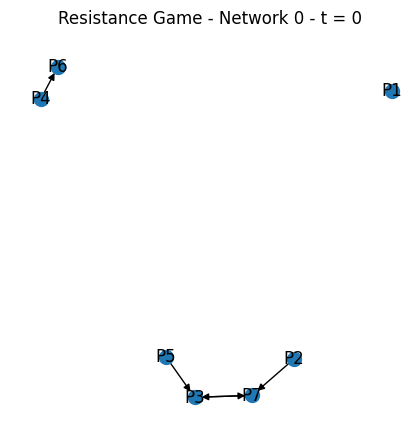

In [17]:
participantes = [
    col.split("_TO_")[0]
    for col in network0.columns
    if "_TO_" in col
]

participantes = sorted(set(participantes))

print(participantes)

G = nx.DiGraph()

G.add_nodes_from(participantes)

fila = network0.iloc[0]

for columna in network0.columns:
    
    if "_TO_" not in columna:
        continue
    
    origen, destino = columna.split("_TO_")
    
    if fila[columna] == 1:
        if destino != "LAPTOP":
            G.add_edge(origen, destino)

print("Nodos:", G.number_of_nodes())
print("Aristas:", G.number_of_edges())

plt.figure(figsize=(4, 4))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=100,
    arrows=True
)

plt.title("Resistance Game - Network 0 - t = 0")
plt.show()

In [13]:
def construir_grafo(row):
    
    G = nx.DiGraph()
    
    for columna in row.index:
        
        if "_TO_" not in columna:
            continue
        
        origen, destino = columna.split("_TO_")
        
        if destino == "LAPTOP":
            continue
        
        if row[columna] == 1:
            G.add_edge(origen, destino)
    
    return G

for i in range(100):
    G = construir_grafo(network0.iloc[i])
    print(f"Grafo {i}: Nodos = {G.number_of_nodes()}, Aristas = {G.number_of_edges()}")


Grafo 0: Nodos = 6, Aristas = 5
Grafo 1: Nodos = 6, Aristas = 6
Grafo 2: Nodos = 6, Aristas = 6
Grafo 3: Nodos = 4, Aristas = 4
Grafo 4: Nodos = 5, Aristas = 5
Grafo 5: Nodos = 5, Aristas = 5
Grafo 6: Nodos = 6, Aristas = 6
Grafo 7: Nodos = 5, Aristas = 5
Grafo 8: Nodos = 6, Aristas = 6
Grafo 9: Nodos = 4, Aristas = 4
Grafo 10: Nodos = 5, Aristas = 5
Grafo 11: Nodos = 6, Aristas = 6
Grafo 12: Nodos = 5, Aristas = 5
Grafo 13: Nodos = 7, Aristas = 7
Grafo 14: Nodos = 7, Aristas = 7
Grafo 15: Nodos = 6, Aristas = 6
Grafo 16: Nodos = 6, Aristas = 6
Grafo 17: Nodos = 7, Aristas = 7
Grafo 18: Nodos = 6, Aristas = 6
Grafo 19: Nodos = 7, Aristas = 6
Grafo 20: Nodos = 7, Aristas = 7
Grafo 21: Nodos = 7, Aristas = 7
Grafo 22: Nodos = 7, Aristas = 7
Grafo 23: Nodos = 7, Aristas = 7
Grafo 24: Nodos = 7, Aristas = 7
Grafo 25: Nodos = 7, Aristas = 7
Grafo 26: Nodos = 7, Aristas = 7
Grafo 27: Nodos = 7, Aristas = 7
Grafo 28: Nodos = 6, Aristas = 6
Grafo 29: Nodos = 6, Aristas = 6
Grafo 30: Nodos = 7,

In [14]:
ruta_weighted = (
    carpeta_salida
    / "network"
    / "network0_weighted.csv"
)

network0_weighted = pd.read_csv(ruta_weighted)

print(network0_weighted.head())

def construir_grafo_weighted(row):
    
    G = nx.DiGraph()
    
    for columna in row.index:
        
        if "_TO_" not in columna:
            continue
        
        origen, destino = columna.split("_TO_")
        
        if destino == "LAPTOP":
            continue
        
        peso = row[columna]
        
        if peso > 0:
            G.add_edge(
                origen,
                destino,
                weight=peso
            )
    
    return G

Gw = construir_grafo_weighted(network0_weighted.iloc[0])

print(Gw.edges(data=True))

   TIME  P1_TO_LAPTOP  P1_TO_P1  P1_TO_P2  P1_TO_P3  P1_TO_P4  P1_TO_P5  \
0   0.0         0.534       0.0     0.046     0.083     0.000     0.041   
1   1.0         0.646       0.0     0.061     0.123     0.000     0.050   
2   2.0         0.730       0.0     0.043     0.088     0.006     0.041   
3   3.0         0.563       0.0     0.079     0.175     0.003     0.058   
4   4.0         0.594       0.0     0.074     0.151     0.004     0.054   

   P1_TO_P6  P1_TO_P7  P2_TO_LAPTOP  ...  P6_TO_P6  P6_TO_P7  P7_TO_LAPTOP  \
0     0.029     0.067         0.077  ...       0.0     0.120         0.094   
1     0.029     0.091         0.086  ...       0.0     0.120         0.017   
2     0.021     0.071         0.086  ...       0.0     0.141         0.031   
3     0.033     0.090         0.111  ...       0.0     0.119         0.043   
4     0.036     0.086         0.200  ...       0.0     0.110         0.043   

   P7_TO_P1  P7_TO_P2  P7_TO_P3  P7_TO_P4  P7_TO_P5  P7_TO_P6  P7_TO_P7  
0     

In [15]:
for i in range(100):
    G = construir_grafo_weighted(network0_weighted.iloc[i])
    print(f"Grafo {i}: Nodos = {G.number_of_nodes()}, Aristas = {G.number_of_edges()}")


Grafo 0: Nodos = 7, Aristas = 41
Grafo 1: Nodos = 7, Aristas = 41
Grafo 2: Nodos = 7, Aristas = 42
Grafo 3: Nodos = 7, Aristas = 42
Grafo 4: Nodos = 7, Aristas = 41
Grafo 5: Nodos = 7, Aristas = 41
Grafo 6: Nodos = 7, Aristas = 42
Grafo 7: Nodos = 7, Aristas = 41
Grafo 8: Nodos = 7, Aristas = 41
Grafo 9: Nodos = 7, Aristas = 41
Grafo 10: Nodos = 7, Aristas = 42
Grafo 11: Nodos = 7, Aristas = 40
Grafo 12: Nodos = 7, Aristas = 41
Grafo 13: Nodos = 7, Aristas = 41
Grafo 14: Nodos = 7, Aristas = 40
Grafo 15: Nodos = 7, Aristas = 41
Grafo 16: Nodos = 7, Aristas = 41
Grafo 17: Nodos = 7, Aristas = 40
Grafo 18: Nodos = 7, Aristas = 41
Grafo 19: Nodos = 7, Aristas = 38
Grafo 20: Nodos = 7, Aristas = 41
Grafo 21: Nodos = 7, Aristas = 41
Grafo 22: Nodos = 7, Aristas = 41
Grafo 23: Nodos = 7, Aristas = 41
Grafo 24: Nodos = 7, Aristas = 39
Grafo 25: Nodos = 7, Aristas = 41
Grafo 26: Nodos = 7, Aristas = 42
Grafo 27: Nodos = 7, Aristas = 42
Grafo 28: Nodos = 7, Aristas = 41
Grafo 29: Nodos = 7, Ari

## Network 2

## Network 3

## Network 4

## Network 5